<a href="https://colab.research.google.com/github/shuob3344/MSSP6070/blob/main/WeeklyModules/Week07/Week7_Participation_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os
import subprocess

github_token = userdata.get('git_hub')

owner = 'shuob3344'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(['git', 'clone', clone_url], check=True)

os.chdir(repository)

import pandas as pd

In [3]:
df = pd.read_csv('data/InternetSales (3).csv', encoding='cp1252')

df.head()

/tmp/ipykernel_1270/1650667817.py:1: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data/InternetSales (3).csv', encoding='cp1252')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [4]:
df[['OrderDate', 'SalesAmount']].head()

,OrderDate,SalesAmount
0,1/19/2011,3399.99
1,1/18/2013,2319.99
2,1/18/2013,21.98
3,5/3/2013,2384.07
4,5/3/2013,28.99


In [5]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year

df[['OrderDate', 'Year', 'SalesAmount']].head()

,OrderDate,Year,SalesAmount
0,2011-01-19,2011,3399.99
1,2013-01-18,2013,2319.99
2,2013-01-18,2013,21.98
3,2013-05-03,2013,2384.07
4,2013-05-03,2013,28.99


In [6]:
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

yearly_sales

,SalesAmount
Year,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


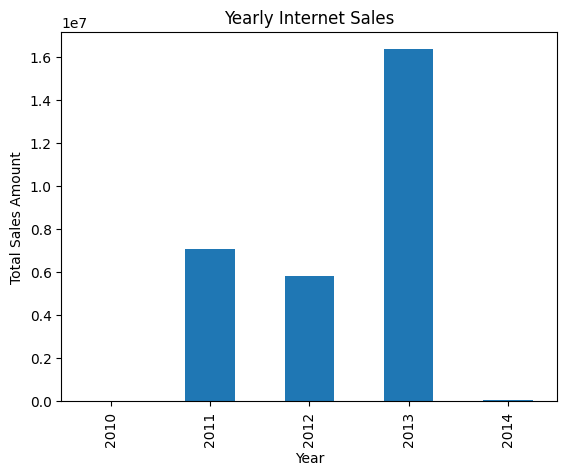

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

yearly_sales.plot.bar(ax=ax)

ax.set_title('Yearly Internet Sales')
ax.set_xlabel('Year')
ax.set_ylabel('Total Sales Amount')

plt.show()

In [8]:
fig.savefig('Week7_Yearly_Sales.pdf', bbox_inches='tight')